# **Experiment Notebook**

In [115]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
nba-longevity-player-25740655 0.4.0 requires pandas!=2.2.3,>=2.0, but you have pandas 2.2.3 which is incompatible.


In [116]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

---
## Student Information

In [117]:
student_name = "Shreeya Patil"
student_id = "25740655"
group_id = "38"

In [118]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [119]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

In [120]:
# Do not modify this code
print_tile(size="h1", key='group_id', value=group_id)

---
## 0. Python Packages

The reusable logic for every experiment in this series lives in the individual package `nba-longevity-player-25740655`. Keeping data loading, player aggregation, evaluation and submission assembly in one installed, unit-tested package means all three experiments use identical definitions, so differences between them are attributable to the modelling change under test rather than to drift between copies of the same helper.

In [121]:
# Install the individual package for this assessment from TestPyPI.
# --extra-index-url is required because TestPyPI does not mirror pandas, numpy,
# scikit-learn or xgboost, so those dependencies resolve from real PyPI.
!pip install -q \
    --index-url https://test.pypi.org/simple/ \
    --extra-index-url https://pypi.org/simple \
    "nba-longevity-player-25740655[xgboost,plots]"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
utstd 0.1.9 requires pandas~=2.2.2, but you have pandas 3.0.5 which is incompatible.


In [122]:
# Fallback for markers: if TestPyPI is unreachable, install from a local copy of
# the package repository. Several conventional locations are searched, so this
# works whether the two repositories are cloned side by side, nested, or the
# package sits one level up.
try:
    import nba_longevity_player  # noqa: F401
    print("nba_longevity_player is importable.")
except ImportError:
    import subprocess, sys
    from pathlib import Path

    PKG_DIR_NAME = "36120-26SP-group38-25740655-package"
    here = Path.cwd()
    candidates = [
        here.parent.parent / PKG_DIR_NAME,   # repos cloned side by side
        here.parent / PKG_DIR_NAME,          # package nested in this repo
        here / PKG_DIR_NAME,
        here.parent.parent.parent / PKG_DIR_NAME,
    ]
    target = next((c for c in candidates if (c / "pyproject.toml").is_file()), None)
    if target is None:
        raise ImportError(
            "Could not install nba_longevity_player. Either allow access to "
            "TestPyPI, or place the package repository "
            f"'{PKG_DIR_NAME}' beside this repository. Searched: "
            + ", ".join(str(c) for c in candidates)
        )
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e",
                           f"{target}[xgboost,plots]"])
    print("Installed nba_longevity_player from:", target)

nba_longevity_player is importable.


In [123]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix, roc_auc_score,
)
from sklearn.model_selection import train_test_split

# Project package (individual package repository, published to TestPyPI)
import nba_longevity_player as nlp
from nba_longevity_player import (
    AGGREGATION_STATS, BAGGING_SEEDS, BEST_PARAMS, CATEGORICAL_FEATURES,
    RANDOM_STATE, RankScorer, SeedBaggedXGB, adversarial_validation,
    align_categoricals, assert_no_target_leakage, audit_player_structure,
    best_threshold_by_f1, build_logistic_pipeline, build_player_table,
    build_random_forest, build_submission, drop_nuisance_features,
    era_shifted_scores, evaluate_predictions, load_competition_data,
    metrics_table, numeric_feature_columns, out_of_fold_predictions,
    plot_precision_recall, prepare_season_rows, save_model, save_submission,
    summarise_cv, threshold_sweep, within_season_zscore,
)

pd.set_option("display.max_columns", 100)
print("nba_longevity_player version:", nlp.__version__)
print("Random state:", RANDOM_STATE)

nba_longevity_player version: 0.4.0
Random state: 42


In [124]:
print("Experiment 1: Logistic Regression baseline")

Experiment 1: Logistic Regression baseline


---
## A. Project Description

In [125]:
business_use_case_description = """
The aim of this project is to predict whether a U.S. college basketball player will go on to have a sustained NBA career, defined as playing at least three NBA seasons. The prediction uses only college-level statistics such as scoring, efficiency, playing time, defensive contribution and advanced performance measures. A reliable model supports the early identification of players whose statistical profile resembles those who lasted, and provides an additional data-driven perspective alongside traditional scouting.
"""

In [126]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [127]:
business_objectives = """
The objective is to rank college players by their likelihood of a sustained NBA career, so that limited scouting capacity can be directed at the most promising candidates first. Both error types carry cost: a false positive consumes evaluation effort that could have gone elsewhere, while a false negative means a genuinely durable player is never examined closely. Because roughly 3.4% of players reach the positive outcome, the model must discriminate well within a severely imbalanced problem rather than simply achieve high accuracy.
"""

In [128]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [129]:
stakeholders_expectations_explanations = """
The direct users are scouts, analysts and basketball operations staff, who would treat the output as a screening and prioritisation tool. Players are indirectly but materially affected, because a low ranking could reduce the attention they receive and therefore their opportunities, which makes this a decision-support system rather than a selection rule. Coaches, agents and college programmes are affected in turn. Users need probability-based rankings, honest validation evidence, reproducible code and a clear statement of limitations, and subgroup performance should be audited before any operational use.
"""

In [130]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## B. Experiment Description

In [131]:
experiment_hypothesis = """
Experiment 1 establishes a Logistic Regression baseline and uses it to test the most consequential design question in this project: at what granularity should the model be trained?

The raw data holds one row per player-season, while the competition scores one prediction per player. A model can therefore be fitted on season rows and its predictions collapsed to players afterwards, or the season rows can be aggregated into one row per player before fitting. Two sub-questions follow: whether aggregating first is better, and if predictions are collapsed afterwards, whether the mean or the maximum is the better rule.

The hypothesis entering this experiment was that aggregating first would be clearly better, because it matches the training unit to the scoring unit. Section J.4 tests that directly and the result does not support it for a linear model, which is reported as found rather than as expected.
"""

In [132]:
# Do not modify this code
print_tile(size="h3", key='experiment_hypothesis', value=experiment_hypothesis)

In [133]:
experiment_expectations = """
Two mechanisms were expected to favour aggregating first. Collapsing predictions afterwards requires an arbitrary rule, and taking a maximum is biased because a four-season player gets four draws at the top while a one-season player gets one. Aggregation also creates information no single season row contains, such as a career peak and the number of seasons played.

One mechanism pushes the other way, and it turns out to matter more for a linear model. Aggregation trades roughly 41,000 training rows for about 17,900, while simultaneously tripling the feature count from 58 to 181 as each statistic becomes a latest, mean and max. For a penalised linear model with only about 600 positive cases, that is a substantially worse-conditioned problem.

A Logistic Regression is chosen deliberately for this comparison because it is the weakest model in the series and has no capacity to exploit the interactions that a richer feature set makes available. It therefore isolates the cost of the representation change from its benefit, and sets up the question Experiments 2 and 3 answer: whether a model that can use the extra features recovers the loss.
"""

In [134]:
# Do not modify this code
print_tile(size="h3", key='experiment_expectations', value=experiment_expectations)

---
## C. Data Understanding

### C.1 Load Datasets

In [135]:
# Runs unchanged on Colab or locally: mounts Drive on Colab, otherwise resolves
# the CSVs through NBA_DATA_DIR or a short list of conventional locations.
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ["NBA_DATA_DIR"] = "/content/drive/MyDrive/AML_AT1/data"
except (ImportError, ModuleNotFoundError):
    print("Not running on Colab; resolving a local data directory.")
    if "NBA_DATA_DIR" not in os.environ:
        here = Path.cwd()
        for candidate in (here, here.parent, here.parent.parent, here.parent / "data" / "raw"):
            if (candidate / "train.csv").is_file():
                os.environ["NBA_DATA_DIR"] = str(candidate)
                break

data = load_competition_data()
train_raw, test_raw = data.train, data.test
metadata, sample_submission = data.metadata, data.sample_submission
target_name = "label"

display(data.describe())
display(train_raw.head())

Not running on Colab; resolving a local data directory.


,table,rows,columns
0,train,41195,66
1,test,12061,65
2,sample_submission,12061,2
3,metadata,66,3


,team,conf,GP,Min_per,ORtg,usg,eFG,TS_per,ORB_per,DRB_per,AST_per,TO_per,FTM,FTA,FT_per,twoPM,twoPA,twoP_per,TPM,TPA,TP_per,blk_per,stl_per,ftr,yr,ht,num,porpag,adjoe,pfr,year,pid,type,Rec Rank,ast/tov,rimmade,rimmade+rimmiss,midmade,midmade+midmiss,rimmade/(rimmade+rimmiss),midmade/(midmade+midmiss),dunksmade,dunksmiss+dunksmade,dunksmade/(dunksmade+dunksmiss),drtg,adrtg,dporpag,stops,bpm,obpm,dbpm,gbpm,mp,ogbpm,dgbpm,oreb,dreb,treb,ast,stl,blk,pts,role,3p/100?,dob,label
0,Detroit Mercy,Horz,6,1.0,0.0,16.8,0.0,0.00,0.0,11.4,0.0,32.9,0,0,0.000,0,2,0.00,0,1,0.000,0.0,5.5,0.0,So,6-7,NaN,-0.596255,-0.350153,13.3,2008,1,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.724,98.5024,0.196087,2.50101,-16.03080,-14.635200,-1.395570,-25.22810,2.0000,-23.72870,-1.499380,0.1429,0.1429,0.2857,0.0000,0.2857,0.0000,0.0000,NaN,5.70546,1987-10-15,0
1,South Alabama,SB,22,8.4,62.0,14.1,32.6,33.40,0.0,5.4,6.6,32.1,1,2,0.500,3,12,0.25,3,11,0.273,0.0,1.1,8.7,Fr,6-2,NaN,-0.502715,55.211000,6.1,2008,2,"Panama City, FL",NaN,0.624962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103.960,104.6870,0.365511,15.03790,-8.20704,-6.196110,-2.010930,-10.82510,5.1250,-8.91292,-1.912160,0.0000,0.3333,0.3333,0.2083,0.0833,0.0000,0.7500,NaN,6.20657,1989-05-19,0
2,Utah St.,WAC,28,24.3,93.1,13.8,45.2,46.20,1.4,6.6,14.3,22.9,7,13,0.538,16,39,0.41,8,23,0.348,0.6,1.7,21.0,Fr,6-4,NaN,-0.081932,83.568300,3.3,2008,3,NaN,NaN,1.449906,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108.419,110.3660,0.672348,48.48480,-3.08320,-0.977192,-2.106010,-2.61135,12.1379,-1.89802,-0.713339,0.1379,0.6897,0.8276,1.0000,0.3793,0.0690,2.4483,NaN,4.26818,1988-07-01,0
3,Arizona,P10,6,1.0,15.8,18.4,0.0,0.00,9.7,0.0,0.0,47.7,0,1,0.000,0,1,0.00,0,1,0.000,7.1,0.0,50.0,Jr,6-9,NaN,-0.567183,15.514200,14.3,2008,4,"Durham, NC",88.6,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.664,108.4130,0.148523,1.81359,-12.22840,-12.814600,0.586230,-20.13640,2.3333,-18.31140,-1.825010,0.1667,0.0000,0.1667,0.0000,0.0000,0.1667,0.0000,NaN,4.60267,1986-10-15,0
4,South Florida,BE,30,71.1,105.8,19.0,50.6,54.16,2.3,8.4,18.8,18.9,53,66,0.803,71,148,0.48,42,117,0.359,0.2,1.2,24.9,Jr,6-4,NaN,2.300420,108.132000,2.1,2008,5,NaN,NaN,1.462945,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.044,103.3630,2.384750,127.00500,1.14550,2.037230,-0.891732,1.69271,29.5000,2.17089,-0.478177,0.6000,2.2333,2.8333,2.6333,0.5667,0.0667,10.7000,NaN,7.81267,1986-10-15,0


### C.2 Define Target variable

In [136]:
print("Target variable:", target_name)
print("Data type:", train_raw[target_name].dtype)
print("Unique values:", sorted(train_raw[target_name].unique()))
if metadata is not None:
    display(metadata[metadata["name"] == target_name][["name", "description"]])

Target variable: label
Data type: int64
Unique values: [np.int64(0), np.int64(1)]


,name,description
65,label,"1 = NBA career ³ 3 seasons, 0 otherwise"


In [137]:
target_definition_explanations = """
The target is `label`, where 1 marks a player who went on to at least three NBA seasons and 0 marks a player who did not. The problem is therefore binary classification and the model outputs a positive-class probability used for ranking. One property of the definition drives the design of every experiment in this series: the label describes a career outcome belonging to the *player*, not to any individual season, even though the raw file repeats it on every season row a player has.
"""

In [138]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [139]:
# The label is a career outcome, so it aggregates to the player with max():
# a player with any positive season counts as positive. This also resolves the
# small number of players whose season rows disagree with one another.
player_label = train_raw.groupby("pid")[target_name].max()

print("Season rows:", len(train_raw))
print("Unique players:", train_raw["pid"].nunique())
print("Row-level positive rate:   ", round(train_raw[target_name].mean(), 4))
print("Player-level positive rate:", round(player_label.mean(), 4))
print("Players with inconsistent season labels:",
      int(train_raw.groupby("pid")[target_name].nunique().gt(1).sum()))

Season rows: 41195
Unique players: 17938
Row-level positive rate:    0.0342
Player-level positive rate: 0.0337
Players with inconsistent season labels: 16


### C.4 Explore Target variable

,Count,Percentage (%)
label,,
0,17334,96.63
1,604,3.37


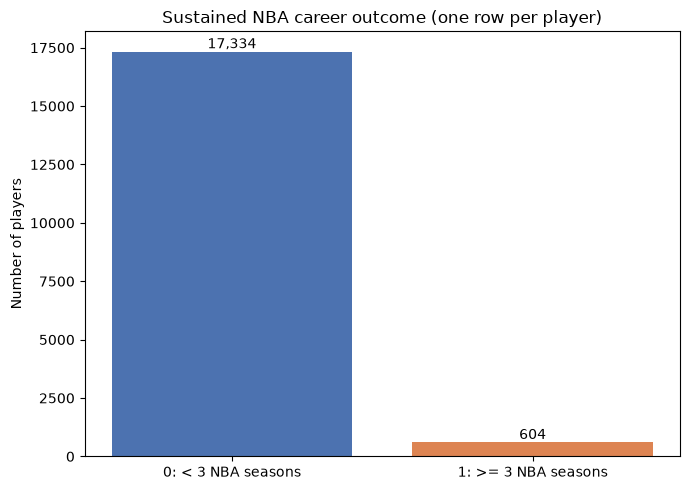

In [140]:
counts = player_label.value_counts().sort_index()
pct = player_label.value_counts(normalize=True).sort_index().mul(100)
display(pd.DataFrame({"Count": counts, "Percentage (%)": pct.round(2)}))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(["0: < 3 NBA seasons", "1: >= 3 NBA seasons"], counts.values,
              color=["#4C72B0", "#DD8452"])
ax.set_title("Sustained NBA career outcome (one row per player)")
ax.set_ylabel("Number of players")
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:,}",
            ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [141]:
target_distribution_explanations = """
The target is highly imbalanced: roughly 96.6% of players fall in class 0 and about 3.4% in the sustained-career class. Accuracy is therefore useless, since predicting the majority class for everybody would score above 96%. AUPRC is the appropriate primary metric because its baseline is the positive rate itself, so a random ranker scores about 0.034 rather than the 0.5 it would score under ROC-AUC. Aggregating from season rows to players barely moves the positive rate, confirming the imbalance is a property of the problem rather than an artefact of repeated rows.
"""

In [142]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `bpm` (Box Plus/Minus)

,name,description
48,bpm,BPM - Estimate the playerâs contribution in ...


,count,mean,median,std,min,max
label,,,,,,
0,39726,-2.688014,-1.958375,8.726875,-88.4466,685.2380
1,1410,3.655853,4.578945,5.121986,-18.3069,48.0997


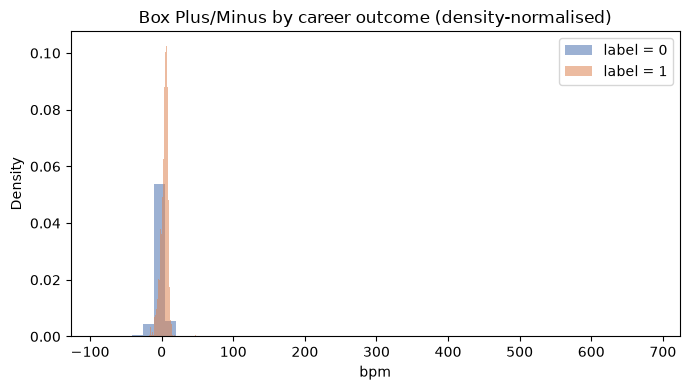

In [143]:
feature_1 = "bpm"
if metadata is not None:
    display(metadata[metadata["name"] == feature_1][["name", "description"]])
display(train_raw.groupby(target_name)[feature_1].agg(
    ["count", "mean", "median", "std", "min", "max"]))

fig, ax = plt.subplots(figsize=(7, 4))
for value, colour in [(0, "#4C72B0"), (1, "#DD8452")]:
    ax.hist(train_raw.loc[train_raw[target_name] == value, feature_1].dropna(),
            bins=50, density=True, alpha=0.55, color=colour, label=f"label = {value}")
ax.set_title("Box Plus/Minus by career outcome (density-normalised)")
ax.set_xlabel(feature_1); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout(); plt.show()

In [144]:
feature_1_insights = """
BPM estimates a player's overall contribution while on the court and is therefore a broad measure of quality. Players who reach sustained NBA careers post clearly higher college BPM, confirming real signal, but the distributions overlap substantially so BPM alone cannot separate the classes. BPM is a rate statistic and becomes unstable over very few minutes, which is why the later experiments carry both a career mean and a career maximum of it: the mean describes the level a player sustained and the maximum his peak, and those answer different scouting questions.
"""

In [145]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `Min_per` (Minutes Percentage)

In [146]:
feature_2 = "Min_per"
if metadata is not None:
    display(metadata[metadata["name"] == feature_2][["name", "description"]])
print(train_raw[feature_2].describe())
print("Missing values:", int(train_raw[feature_2].isnull().sum()))
display(train_raw.groupby(target_name)[feature_2].agg(
    ["count", "mean", "median", "std", "min", "max"]))

,name,description
3,Min_per,Player's percentage of available team minutes ...


count    41195.000000
mean        37.235689
std         27.973792
min          0.000000
25%          9.600000
50%         35.800000
75%         62.000000
max         98.000000
Name: Min_per, dtype: float64
Missing values: 0


,count,mean,median,std,min,max
label,,,,,,
0,39785,36.447465,34.5,27.757516,0.0,98.0
1,1410,59.476454,66.8,24.715902,0.1,94.5


In [147]:
feature_2_insights = """
Min_per measures the share of available team minutes a player received and therefore reflects how heavily his coach relied on him. Players who eventually sustain NBA careers receive a noticeably greater share, and the feature has no missing values. It also supplies the context needed to read rate statistics: a high BPM earned in limited garbage-time minutes should not be interpreted like the same figure sustained across a starter's workload.
"""

In [148]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `height_inches` (parsed from `ht`)

In [149]:
# This feature does not exist in the raw file: `ht` arrives as text such as '6-7'.
# A pipeline selecting numeric columns only would discard it without warning.
probe = prepare_season_rows(train_raw)
feature_3 = "height_inches"
print("Raw `ht` examples:", train_raw["ht"].dropna().unique()[:6].tolist())
print("Parsed to inches: ", probe[feature_3].dropna().unique()[:6].tolist())
print("Unparseable rows:", int(probe[feature_3].isna().sum()))
display(probe.groupby(target_name)[feature_3].agg(
    ["count", "mean", "median", "std", "min", "max"]))

Raw `ht` examples: ['6-7', '6-2', '6-4', '6-9', '6-3', '6-8']
Parsed to inches:  [79.0, 74.0, 76.0, 81.0, 75.0, 80.0]
Unparseable rows: 409


,count,mean,median,std,min,max
label,,,,,,
0,39377,76.680270,77.0,3.634527,48.0,91.0
1,1409,77.912704,78.0,3.319436,67.0,90.0


In [150]:
feature_3_insights = """
Height is a well-established constraint on NBA roles and the group means differ meaningfully between the classes, so it carries genuine predictive information. It is highlighted here because it illustrates a failure mode this series corrects: the raw column `ht` stores values as text such as '6-7', so a pipeline that selects numeric columns silently discards it, along with date of birth, jersey number, conference, year level and role. Parsing it into inches costs three lines and recovers a real predictor; the same reasoning recovers age at season from date of birth.
"""

In [151]:
# Do not modify this code
print_tile(size="h3", key='feature_3_insights', value=feature_3_insights)

### C.n Broader Data Understanding

In [152]:
display(audit_player_structure(train_raw, test_raw))

,check,value
0,train_rows,41195
1,train_unique_players,17938
2,players_with_multiple_rows,11906
3,max_rows_for_one_player,9
4,test_rows,12061
5,test_unique_players,6261
6,train_year_range,2008-2016
7,test_year_range,2020-2023
8,players_with_inconsistent_labels,16
9,row_positive_rate,0.0342


In [153]:
missing = pd.DataFrame({
    "Missing Count": train_raw.isnull().sum(),
    "Missing Percentage (%)": (train_raw.isnull().mean() * 100).round(2),
})
missing = missing[missing["Missing Count"] > 0].sort_values(
    "Missing Percentage (%)", ascending=False)
print("Columns containing missing values:", len(missing))
display(missing.head(20))

Columns containing missing values: 26


,Missing Count,Missing Percentage (%)
Rec Rank,28359,68.84
dunksmade/(dunksmade+dunksmiss),25784,62.59
type,18153,44.07
rimmade/(rimmade+rimmiss),12071,29.30
midmade/(midmade+midmiss),12006,29.14
rimmade,9963,24.18
rimmade+rimmiss,9963,24.18
midmade,9963,24.18
midmade+midmiss,9963,24.18
dunksmade,9963,24.18


In [154]:
player_structure_explanations = """
The audit contains the two observations that shape this entire experiment series. First, the data is stored at player-season level and most players appear more than once, while the leaderboard scores one prediction per player; training on season rows therefore answers a different question from the one being marked. Second, the training set covers 2008-2016 while the Kaggle test set covers 2020-2023 with no overlap at all. That gap is why absolute season year is excluded from every feature set, and why cross-validated results drawn from within the training years must be treated as optimistic rather than as a forecast of leaderboard performance.
"""

In [155]:
# Do not modify this code
print_tile(size="h3", key='player_structure_explanations', value=player_structure_explanations)

---
## D. Feature Selection

### D.1 Approach "Parse text columns rather than discarding them"

In [156]:
train_season = prepare_season_rows(train_raw)
test_season = prepare_season_rows(test_raw)
numeric_columns = numeric_feature_columns(train_season, test_season)

print("Numeric predictors available in both train and test:", len(numeric_columns))
print("Recovered from text columns:", ["height_inches", "age_at_season", "jersey_number"])
print("Categorical predictors:", list(CATEGORICAL_FEATURES))
assert_no_target_leakage(numeric_columns, test_season)
print("Leakage check passed.")

Numeric predictors available in both train and test: 58
Recovered from text columns: ['height_inches', 'age_at_season', 'jersey_number']
Categorical predictors: ['conf', 'yr', 'role']
Leakage check passed.


In [157]:
feature_selection_1_insights = """
The first step is a correction rather than a filter. Three raw columns carry usable signal but arrive as text, so a numeric-only selection drops them: `ht` such as '6-7' becomes height in inches, `dob` becomes age at season, and `num` becomes a numeric jersey number. Values that cannot be parsed become missing rather than raising, so one malformed row cannot abort the load. Conference, year level and role are retained as categorical predictors.
"""

In [158]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Require presence in both train and test"

In [159]:
only_in_train = sorted(set(train_season.select_dtypes(include=np.number).columns)
                       - set(test_season.columns))
print("Numeric columns present in train but not test:", only_in_train)
print("Retained predictors:", len(numeric_columns))

Numeric columns present in train but not test: ['label']
Retained predictors: 58


In [160]:
feature_selection_2_insights = """
Predictors must exist in both the training and Kaggle test frames, which converts a failure that would otherwise surface only at submission time into an immediate one. No missingness threshold is applied at this stage. Because Logistic Regression cannot consume missing values, they are median-imputed inside the modelling pipeline, so the imputer is fitted on training data only and cannot leak validation information. This is a genuine disadvantage of the linear model and is revisited in Experiment 3, where XGBoost handles missing values natively.
"""

In [161]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.n Approach "Exclude identifiers and era-encoding columns"

In [162]:
print("Excluded from model inputs:", list(nlp.ID_COLUMNS))
print("Train years:", sorted(train_raw["year"].unique()))
print("Test years: ", sorted(test_raw["year"].unique()))
print("Overlapping years:",
      sorted(set(train_raw["year"]) & set(test_raw["year"])) or "none")

Excluded from model inputs: ['label', 'pid', 'year']
Train years: [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]
Test years:  [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Overlapping years: none


In [163]:
feature_selection_n_insights = """
Player id, the target and absolute season year are excluded from the model inputs. Player id is an arbitrary key that would be meaningless for the unseen test players. Absolute year is excluded because the training and test year ranges do not overlap at all, so any coefficient on year would encode an era the model will never see again. Only the derived career span survives from the year column, measuring how long a player stayed in college rather than when he played.
"""

In [164]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_n_insights', value=feature_selection_n_insights)

## D.z Final Selection of Features

In [165]:
print("Numeric source statistics:", len(numeric_columns))
print("Aggregations applied:", list(AGGREGATION_STATS))
print("Categorical predictors:", list(CATEGORICAL_FEATURES))

Numeric source statistics: 58
Aggregations applied: ['latest', 'mean', 'max']
Categorical predictors: ['conf', 'yr', 'role']


In [166]:
feature_selection_explanations = """
The final source set is every numeric statistic available in both frames, the three columns recovered from text, and three categorical descriptors. These are expanded by aggregation in Section F. Linear correlation with the target is deliberately not used as a selection criterion: it would be a defensible filter for a linear model but would bias the comparison in Section J.4 against the tree-based experiments that follow, which exploit non-linear and interaction effects a univariate correlation cannot see. Keeping the feature set identical across all three experiments is what makes their results comparable.
"""

In [167]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "Clean the season rows"

In [168]:
print("Season frames after cleaning:")
print("  train:", train_season.shape)
print("  test: ", test_season.shape)
print("Infinite values remaining:",
      int(np.isinf(train_season.select_dtypes(include=np.number).to_numpy()).sum()))

Season frames after cleaning:
  train: (41195, 65)
  test:  (12061, 64)
Infinite values remaining: 0


In [169]:
data_cleaning_1_explanations = """
Cleaning happens at season level, before any aggregation, so every derived statistic is computed from corrected values. Infinite values are converted to missing because an infinity breaks a model fit outright, whereas a missing value can be imputed deliberately. The remaining missing values are left in place at this stage and handled inside the modelling pipeline, which keeps the imputer fitted on training data only.
"""

In [170]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "Aggregate to one row per player"

In [171]:
player_train = build_player_table(train_season, numeric_columns, include_target=True)
player_test = build_player_table(test_season, numeric_columns, include_target=False)

print("Player-level train:", player_train.shape)
print("Player-level test: ", player_test.shape)
print("One row per player:", player_train["pid"].is_unique, player_test["pid"].is_unique)
print("Test rows match the submission requirement:",
      len(player_test) == nlp.EXPECTED_SUBMISSION_ROWS)
display(player_train.head())

Player-level train: (17938, 183)
Player-level test:  (6261, 182)
One row per player: True True
Test rows match the submission requirement: True


,pid,conf,yr,role,GP_latest,Min_per_latest,ORtg_latest,usg_latest,eFG_latest,TS_per_latest,ORB_per_latest,DRB_per_latest,AST_per_latest,TO_per_latest,FTM_latest,FTA_latest,FT_per_latest,twoPM_latest,twoPA_latest,twoP_per_latest,TPM_latest,TPA_latest,TP_per_latest,blk_per_latest,stl_per_latest,ftr_latest,porpag_latest,adjoe_latest,pfr_latest,Rec Rank_latest,ast/tov_latest,rimmade_latest,rimmade+rimmiss_latest,midmade_latest,midmade+midmiss_latest,rimmade/(rimmade+rimmiss)_latest,midmade/(midmade+midmiss)_latest,dunksmade_latest,dunksmiss+dunksmade_latest,dunksmade/(dunksmade+dunksmiss)_latest,drtg_latest,adrtg_latest,dporpag_latest,stops_latest,bpm_latest,obpm_latest,dbpm_latest,gbpm_latest,mp_latest,ogbpm_latest,...,dunksmade/(dunksmade+dunksmiss)_max,drtg_mean,drtg_max,adrtg_mean,adrtg_max,dporpag_mean,dporpag_max,stops_mean,stops_max,bpm_mean,bpm_max,obpm_mean,obpm_max,dbpm_mean,dbpm_max,gbpm_mean,gbpm_max,mp_mean,mp_max,ogbpm_mean,ogbpm_max,dgbpm_mean,dgbpm_max,oreb_mean,oreb_max,dreb_mean,dreb_max,treb_mean,treb_max,ast_mean,ast_max,stl_mean,stl_max,blk_mean,blk_max,pts_mean,pts_max,3p/100?_mean,3p/100?_max,height_inches_mean,height_inches_max,age_at_season_mean,age_at_season_max,jersey_number_mean,jersey_number_max,career_observations,seasons_observed,teams_observed,career_span_years,label
0,1,Horz,So,NaN,6,1.0,0.0,16.8,0.0,0.00,0.0,11.4,0.0,32.9,0,0,0.000,0,2,0.000,0,1,0.000,0.0,5.5,0.0,-0.596255,-0.350153,13.3,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.724,98.5024,0.196087,2.50101,-16.030800,-14.63520,-1.395570,-25.228100,2.0000,-23.728700,...,NaN,100.72400,100.724,98.50240,98.5024,0.196087,0.196087,2.50101,2.50101,-16.030800,-16.03080,-14.635200,-14.63520,-1.395570,-1.395570,-25.228100,-25.22810,2.000000,2.0000,-23.728700,-23.728700,-1.499380,-1.499380,0.14290,0.1429,0.14290,0.1429,0.28570,0.2857,0.000000,0.0000,0.285700,0.2857,0.000000,0.0000,0.000000,0.0000,5.705460,5.70546,79.0,79.0,21.00,21,NaN,NaN,1,1,1,0,0
1,2,SB,So,NaN,26,29.5,97.3,16.6,42.5,44.43,1.6,4.6,15.8,16.3,10,14,0.714,26,68,0.382,13,39,0.333,0.3,1.5,13.1,0.215254,89.482800,2.5,NaN,1.823646,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108.321,108.5270,0.893017,49.96440,-4.995140,-1.62336,-3.371780,-4.723150,14.5769,-2.781990,...,NaN,106.14050,108.321,106.60700,108.5270,0.629264,0.893017,32.50115,49.96440,-6.601090,-4.99514,-3.909735,-1.62336,-2.691355,-2.010930,-7.774125,-4.72315,9.850950,14.5769,-5.847455,-2.781990,-1.926655,-1.912160,0.09615,0.1923,0.47435,0.6154,0.57050,0.8077,0.700300,1.1923,0.214750,0.3462,0.019250,0.0385,2.317300,3.8846,6.213415,6.22026,74.0,74.0,19.50,20,NaN,NaN,2,2,1,1,0
2,3,WAC,Jr,Combo G,32,64.0,108.3,18.1,53.0,53.33,2.3,5.9,14.6,14.1,33,62,0.532,70,134,0.522,36,100,0.360,0.9,1.4,26.5,1.801170,104.802000,2.7,NaN,1.999909,48.0,75.0,22.0,59.0,0.64,0.3729,6.0,7.0,0.8571,100.875,98.6094,2.748470,124.82700,2.258600,2.41515,-0.156556,1.048270,27.3125,0.656208,...,0.8571,103.81175,108.419,102.90045,110.3660,2.012329,2.748470,102.51695,124.82700,0.506756,2.25860,1.309650,2.41515,-0.802898,-0.156556,-0.203751,1.04827,22.823075,27.3125,-0.159467,0.656208,-0.044289,0.392058,0.43800,0.6765,1.17610,1.3750,1.61410,1.9412,1.799625,2.1875,0.494675,0.5938,0.185475,0.2353,6.487975,8.7812,5.703407,7.30085,75.5,76.0,21.25,22,5.0,5.0,4,3,1,2,0
3,4,P10,Jr,NaN,6,1.0,15.8,18.4,0.0,0.00,9.7,0.0,0.0,47.7,0,1,0.000,0,1,0.000,0,1,0.000,7.1,0.0,50.0,-0.567183,15.514200,14.3,88.6,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.664,108.4130,0.148523,1.81359,-12.228400,-12.81460,0.586230,-20.136400,2.3333,-18.311400,...,NaN,107.66400,107.664,108.41300,108.4130,0.148523,0.148523,1.81359,1.81359,-12.228400,-12.22840,-12.814600,-12.81460,0.586230,0.586230,-20.136400,-20.13640,2.333300,2.3333,-18.311400,-18.311400,-1.825010,-1.825010,0.16670,0.1667,0.00000,0.0000,0.16670,0.1667,0.000000,0.0000,0.000000,0.0000,0.166700,0.1667,0.000000,0.0000,4.602670,4.60267,81.0,81.0,22.00,22,NaN,NaN,1,1,1,0,0
4,5,BE,Sr,NaN,27,72.0,96.2,21.8,45.7,47.98,2.1,8.0,14.7,15.9,45,67,0

In [172]:
data_cleaning_2_explanations = """
Each player's season rows are collapsed into exactly one row, so the unit the model is trained on is the unit the competition scores. Because the table now holds one row per player, ordinary stratified splitting cannot leak a player across a partition and the grouped splitting a season-level design would require becomes unnecessary by construction. Test rows are emitted in first-seen order, keeping them aligned with the ids the competition supplies and making the final CSV deterministic. The direct comparison against the season-level alternative is run in Section J.4.
"""

In [173]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "Missing-value strategy"

In [174]:
feature_columns = [c for c in player_train.columns if c not in ("pid", target_name)]
missing_after = player_train[feature_columns].isna().sum()
missing_after = missing_after[missing_after > 0].sort_values(ascending=False)
print("Player-level features with missing values:", len(missing_after))
display(missing_after.head(12).to_frame("missing_players"))

Player-level features with missing values: 71


,missing_players
Rec Rank_latest,13106
Rec Rank_max,13100
Rec Rank_mean,13100
dunksmade/(dunksmade+dunksmiss)_latest,11205
dunksmade/(dunksmade+dunksmiss)_max,10411
dunksmade/(dunksmade+dunksmiss)_mean,10411
rimmade/(rimmade+rimmiss)_latest,5045
midmade/(midmade+midmiss)_latest,5014
rimmade/(rimmade+rimmiss)_max,4715
rimmade/(rimmade+rimmiss)_mean,4715


In [175]:
data_cleaning_3_explanations = """
Aggregation changes the missingness pattern but does not remove it: a player whose only season lacks a statistic still lacks it afterwards. Because Logistic Regression cannot consume missing values, these are median-imputed within the pipeline, fitted on the training partition only. Median imputation is a compromise rather than a neutral choice, since missingness here is not random: a statistic is often absent precisely because a player played too few minutes for it to be computed, so imputing a median invents a figure the player never posted and erases that evidence. Experiment 3 removes this compromise by using a model that handles missing values natively.
"""

In [176]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.n Fixing / Final Data Quality Check

In [177]:
X_all = player_train.drop(columns=["pid", target_name])
y_all = player_train[target_name].astype(int).to_numpy()
X_kaggle_raw = player_test.drop(columns=["pid"])
all_pids = player_train["pid"].to_numpy()
test_pids = player_test["pid"].to_numpy()

for column in nlp.ID_COLUMNS:
    assert column not in X_all.columns, f"{column} leaked into the features"
assert list(X_all.columns) == list(X_kaggle_raw.columns)
for leaked in ("year", "first_season", "last_season"):
    assert leaked not in X_all.columns

print("All preparation checks passed.")
print("Players:", len(X_all), " Features:", X_all.shape[1],
      " Positives:", int(y_all.sum()), f"({y_all.mean():.2%})")

All preparation checks passed.
Players: 17938  Features: 181  Positives: 604 (3.37%)


In [178]:
data_cleaning_n_explanations = """
The checks are written as assertions rather than printed output so a violation stops the notebook immediately instead of producing results that look plausible but rest on a broken matrix. Three properties are enforced: no identifier or target reaches the model, the training and Kaggle matrices describe an identical feature space, and no absolute season column survived aggregation. The last matters specifically because of the 2008-2016 against 2020-2023 gap.
"""

In [179]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_n_explanations', value=data_cleaning_n_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Latest-season statistics"

In [180]:
latest_features = [c for c in X_all.columns if c.endswith("_latest")]
print("Latest-season features:", len(latest_features))
display(player_train[["pid"] + latest_features[:6]].head())

Latest-season features: 58


,pid,GP_latest,Min_per_latest,ORtg_latest,usg_latest,eFG_latest,TS_per_latest
0,1,6,1.0,0.0,16.8,0.0,0.00
1,2,26,29.5,97.3,16.6,42.5,44.43
2,3,32,64.0,108.3,18.1,53.0,53.33
3,4,6,1.0,15.8,18.4,0.0,0.00
4,5,27,72.0,96.2,21.8,45.7,47.98


In [181]:
feature_engineering_1_explanations = """
For each source statistic, the value from the player's most recent observed season is carried forward, identified by a stable sort on year followed by taking the last row per player so the choice is deterministic. The final college season is the observation closest to an NBA transition, and a player who improved sharply as a senior is a different prospect from one who peaked as a freshman, a distinction a career average alone cannot express.
"""

In [182]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Career mean and maximum"

In [183]:
mean_features = [c for c in X_all.columns if c.endswith("_mean")]
max_features = [c for c in X_all.columns if c.endswith("_max")]
print("Career mean features:", len(mean_features))
print("Career max features: ", len(max_features))
display(player_train[["pid", "bpm_latest", "bpm_mean", "bpm_max"]].head())

Career mean features: 58
Career max features:  58


,pid,bpm_latest,bpm_mean,bpm_max
0,1,-16.030800,-16.030800,-16.03080
1,2,-4.995140,-6.601090,-4.99514
2,3,2.258600,0.506756,2.25860
3,4,-12.228400,-12.228400,-12.22840
4,5,0.003161,0.574330,1.14550


In [184]:
feature_engineering_validation_explanations = """
Career mean and maximum are computed within each player across his observed seasons. The mean describes the level a player sustained and the maximum his peak, and these answer genuinely different questions: a consistent contributor and a player with one exceptional season can share an identical mean while differing sharply at the maximum. Both are produced by a single package function applied identically to the training and Kaggle frames, which is what guarantees the two cannot drift apart.
"""

In [185]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_validation_explanations', value=feature_engineering_validation_explanations)

### F.3 New Feature "Career experience summary"

In [186]:
summary_features = ["career_observations", "seasons_observed",
                    "teams_observed", "career_span_years"]
display(player_train[summary_features].describe().round(2))
experience = player_train.groupby("seasons_observed")[target_name].agg(["mean", "size"])
experience.columns = ["positive_rate", "players"]
display(experience)

,career_observations,seasons_observed,teams_observed,career_span_years
count,17938.00,17938.00,17938.00,17938.00
mean,2.30,2.04,1.10,1.22
std,1.19,0.99,0.31,1.22
min,1.00,1.00,1.00,0.00
25%,1.00,1.00,1.00,0.00
50%,2.00,2.00,1.00,1.00
75%,3.00,3.00,1.00,2.00
max,9.00,5.00,3.00,6.00


,positive_rate,players
seasons_observed,,
1,0.030884,6832
2,0.036410,5136
3,0.033698,4481
4,0.037370,1445
5,0.022727,44


In [187]:
feature_engineering_n_explanations = """
Four features summarise a player's college experience rather than his production: row count, distinct seasons, teams played for, and the span between first and last season. Team count captures transfers and the span distinguishes four consecutive years at one programme from an interrupted career.

The table also quantifies the bias in aggregating predictions after the fact. Positive rates rise only slightly with seasons observed, from roughly 3.1% at one season to 3.7% at four, yet taking the maximum of four season predictions gives a four-season player four opportunities to record a high score against a single-season player's one. The inflation that produces is far larger than the 0.6 percentage-point difference it would be approximating.
"""

In [188]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.n Fixing "Locking the final feature matrix"

In [189]:
X_all, X_kaggle = align_categoricals(X_all, X_kaggle_raw)
final_features = X_all.columns.tolist()
print("Final feature count:", len(final_features))
print("  latest:", len(latest_features), " mean:", len(mean_features),
      " max:", len(max_features), " categorical:", len(CATEGORICAL_FEATURES),
      " experience:", len(summary_features))

Final feature count: 181
  latest: 58  mean: 58  max: 58  categorical: 3  experience: 4


---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [190]:
# The table is already one row per player, so a stratified split cannot place
# the same athlete on both sides. Stratifying preserves the ~3.4% positive rate.
train_idx, val_idx = train_test_split(
    np.arange(len(X_all)), test_size=0.20, random_state=RANDOM_STATE, stratify=y_all)

X_train, y_train = X_all.iloc[train_idx], y_all[train_idx]
X_val, y_val = X_all.iloc[val_idx], y_all[val_idx]

display(pd.DataFrame({
    "rows": [len(X_train), len(X_val)],
    "positives": [int(y_train.sum()), int(y_val.sum())],
    "positive_rate_%": [round(y_train.mean() * 100, 2), round(y_val.mean() * 100, 2)],
}, index=["train", "validation"]))

overlap = set(all_pids[train_idx]) & set(all_pids[val_idx])
print("Players appearing in both partitions:", len(overlap))

,rows,positives,positive_rate_%
train,14350,483,3.37
validation,3588,121,3.37


Players appearing in both partitions: 0


In [191]:
data_splitting_explanations = """
Because aggregation already produced one row per player, a plain stratified split suffices and player overlap between partitions is zero by construction, as the printed overlap confirms. Stratification preserves the roughly 3.4% positive rate in both partitions, which matters because a single unlucky split can otherwise leave too few positives for average precision to be measured stably. The validation partition is used for reporting; model comparison itself is done by cross-validation over the full training set rather than against this one split.
"""

In [192]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Confirm the modelling matrices"

In [193]:
def matrix_quality(frame):
    numeric = frame.select_dtypes(include=np.number)
    return {"missing_values": int(frame.isna().sum().sum()),
            "infinite_values": int(np.isinf(numeric.to_numpy()).sum()),
            "columns": frame.shape[1]}

quality = pd.DataFrame([matrix_quality(f) for f in (X_train, X_val, X_kaggle)],
                       index=["train", "validation", "kaggle"])
display(quality)
assert quality["infinite_values"].sum() == 0, "infinite values would break training"
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_kaggle.columns)
print("All three matrices share the same columns in the same order.")

,missing_values,infinite_values,columns
train,148744,0,181
validation,35890,0,181
kaggle,35704,0,181


All three matrices share the same columns in the same order.


In [194]:
data_transformation_1_explanations = """
The matrices are asserted to share identical columns in identical order rather than merely printed for inspection, because a silent reordering between fitting and prediction would produce plausible-looking but meaningless probabilities that no downstream check would catch.
"""

In [195]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "Standardisation for the linear model"

In [196]:
pipeline = build_logistic_pipeline()
print(pipeline)
print()
print("Steps:", list(pipeline.named_steps))

Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()),
                ('model',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    max_iter=5000, random_state=42))])

Steps: ['impute', 'scale', 'model']


In [197]:
data_transformation_2_explanations = """
Median imputation and standardisation are applied inside a scikit-learn pipeline rather than to the matrices directly, so both are fitted on the training fold only and cannot leak validation information. Standardisation is required here because a penalised linear model expresses its coefficients in the units of the features, so an unscaled matrix makes the L2 penalty punish large-unit features arbitrarily. This is specific to the linear model: Experiments 2 and 3 use tree ensembles whose splits depend only on rank ordering, where any monotonic rescaling would leave the fitted model unchanged and a scaler would add a preprocessing step with no effect on results.
"""

In [198]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Build the Kaggle test matrix"

In [199]:
print("Kaggle matrix:", X_kaggle.shape)
print("Rows expected by the competition:", nlp.EXPECTED_SUBMISSION_ROWS)
print("Row count matches:", len(X_kaggle) == nlp.EXPECTED_SUBMISSION_ROWS)
print("Ids match sample_submission:", set(test_pids) == set(sample_submission["pid"]))

Kaggle matrix: (6261, 181)
Rows expected by the competition: 6261
Row count matches: True
Ids match sample_submission: True


In [200]:
data_transformation_3_explanations = """
The Kaggle matrix is produced by the same package function that produced the training matrix, so every feature is defined identically for data the model was trained on and data it will be scored on. Two assertions confirm the result is submittable: the row count equals the number of players the competition expects, and the id set matches the supplied sample submission exactly. That second check is the one worth having, because a file with the right shape but the wrong ids scores near zero and reports no error.
"""

In [201]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

In [202]:
from pathlib import Path
from types import SimpleNamespace

def repo_root():
    """Locate the repository root regardless of the working directory.

    VS Code, Jupyter Lab and nbconvert each pick a different default working
    directory, so a bare relative path such as "../data" resolves differently
    depending on how the notebook was launched. Searching upward for the
    repository's own marker directories makes every output path stable.
    """
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    return here

REPO = repo_root()
print("Repository root resolved to:", REPO)

default_output = REPO / "data" / "processed" / "experiment_1"
colab_output = Path("/content/drive/MyDrive/AML_AT1/experiment_1/processed")
save_path = colab_output if Path("/content/drive").exists() else default_output
save_path.mkdir(parents=True, exist_ok=True)
at = SimpleNamespace(folder_path=save_path)

# The template's save cell expects a y_test object. Kaggle test labels are not
# published, so an empty labelled Series is used and documented as such.
X_test = X_kaggle
y_test = pd.Series(name=target_name, dtype="int64")
print("Datasets will be saved to:", at.folder_path.resolve())

Repository root resolved to: /Users/shreeyapatil/Downloads/NEW ASSIGNMENTB 1/FINAL/36120-26SP-group38-experiments
Datasets will be saved to: /Users/shreeyapatil/Downloads/NEW ASSIGNMENTB 1/FINAL/36120-26SP-group38-experiments/data/processed/experiment_1


---
## H. Save Datasets

> Do not change this code

In [203]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(at.folder_path / 'X_train.csv', index=False)
  y_train.to_csv(at.folder_path / 'y_train.csv', index=False)

  X_val.to_csv(at.folder_path / 'X_val.csv', index=False)
  y_val.to_csv(at.folder_path / 'y_val.csv', index=False)

  X_test.to_csv(at.folder_path / 'X_test.csv', index=False)
  y_test.to_csv(at.folder_path / 'y_test.csv', index=False)
except Exception as e:
  print(e)

'numpy.ndarray' object has no attribute 'to_csv'


---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate

In [204]:
# This table is the argument for the metric choice. It scores three deliberately
# useless models against the validation labels; a metric that rewards them
# cannot be trusted for this problem.
rng = np.random.default_rng(RANDOM_STATE)
degenerate = {
    "always predicts 0": np.zeros(len(y_val)),
    "always predicts 1": np.ones(len(y_val)),
    "uniform random": rng.random(len(y_val)),
}
rows = []
for name, scores in degenerate.items():
    preds = (scores >= 0.5).astype(int)
    rows.append({"model": name,
                 "accuracy": (preds == y_val).mean(),
                 "roc_auc": roc_auc_score(y_val, scores) if len(np.unique(scores)) > 1 else np.nan,
                 "auprc": average_precision_score(y_val, scores)})
display(pd.DataFrame(rows).round(4))
print("Positive class rate (the AUPRC baseline):", round(y_val.mean(), 4))

,model,accuracy,roc_auc,auprc
0,always predicts 0,0.9663,NaN,0.0337
1,always predicts 1,0.0337,NaN,0.0337
2,uniform random,0.5022,0.508,0.0344


Positive class rate (the AUPRC baseline): 0.0337


In [205]:
performance_metrics_explanations = """
AUPRC, reported as average precision, is the primary metric because it is what the competition scores and because the target is severely imbalanced at roughly 3.4% positive.

The comparison above shows why the alternatives fail. A model predicting the negative class for every player achieves about 96.6% accuracy while identifying no future NBA players at all, which disqualifies accuracy outright. ROC-AUC is more subtle but still misleading: it is computed from true-positive and false-positive rates, and because the negative class is roughly twenty-eight times larger, a large absolute number of false positives moves the false-positive rate only slightly. A model can therefore post a respectable ROC-AUC while the players it ranks highest are overwhelmingly wrong, which is precisely the failure a scouting department would experience. AUPRC uses precision in place of the false-positive rate and so responds directly to that failure.

ROC-AUC is still reported as a secondary metric for comparability across the three experiments, and precision, recall and F1 are examined across thresholds in Section J.4. Lift over the AUPRC baseline is reported too, because a raw AUPRC value means very different things at different base rates.
"""

In [206]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit

In [207]:
print("Algorithm: Logistic Regression (L2 penalised, class_weight='balanced')")
print(build_logistic_pipeline().named_steps["model"])

Algorithm: Logistic Regression (L2 penalised, class_weight='balanced')
LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000,
                   random_state=42)


In [208]:
algorithm_selection_explanations = """
Experiment 1 uses L2-penalised Logistic Regression. It is chosen deliberately as the weakest model in the series, for three reasons.

First, it provides an interpretable baseline: coefficients state the direction and relative strength of each standardised feature, which is useful for sanity-checking that the model has learned basketball-plausible relationships rather than an artefact.

Second, it is the fairest instrument for the representation comparison that is the real subject of this experiment. If season-level and player-level training differ even under a linear model with no capacity to exploit interactions, the difference is attributable to the data layout rather than to model flexibility.

Third, it establishes the floor against which Experiments 2 and 3 must justify their additional complexity. A more complex model that fails to beat this baseline by a margin exceeding fold-to-fold noise has not earned its place.

Its limitations are equally clear and motivate the later experiments: it can only represent an additive combination of features, so it cannot express that a high usage rate is favourable for an efficient scorer and unfavourable for an inefficient one, and it requires imputation because it cannot consume missing values.
"""

In [209]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe these hyperparameters are a good fit

In [210]:
from sklearn.model_selection import StratifiedKFold

candidates = [0.01, 0.1, 1.0]
rows = []
for C in candidates:
    oof, per_fold = out_of_fold_predictions(
        lambda C=C: RankScorer(build_logistic_pipeline(C=C)), X_all, y_all, n_splits=5)
    rows.append({"C": C, "oof_auprc": round(average_precision_score(y_all, oof), 4)})
display(pd.DataFrame(rows))
best_C = max(rows, key=lambda r: r["oof_auprc"])["C"]
print("Selected C:", best_C)

,C,oof_auprc
0,0.01,0.4364
1,0.10,0.4142
2,1.00,0.3923


Selected C: 0.01


In [211]:
hyperparameters_selection_explanations = """
Only two hyperparameters matter for this model and both are set on evidence rather than by default. The inverse regularisation strength C is chosen from a small grid by five-fold cross-validated AUPRC; the search is deliberately small because a linear model on this feature set has little capacity to be tuned into a materially better result, and an exhaustive search would risk selecting noise. Class weighting is set to 'balanced', which reweights the loss by inverse class frequency so the roughly 3.4% positive class is not ignored in favour of the majority.

One caveat applies to this and every cross-validated number in the series. The folds are drawn at random from within the 2008-2016 training years, while the Kaggle test set covers 2020-2023. Random folds therefore measure same-era ranking, which is an easier problem than the leaderboard poses. Experiment 3 quantifies that gap directly and adopts an era-shifted selection criterion in response.
"""

In [212]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [213]:
model = RankScorer(build_logistic_pipeline(C=best_C)).fit(X_train, y_train)
print("Fitted:", model.model_.named_steps["model"])

Fitted: LogisticRegression(C=0.01, class_weight='balanced', max_iter=5000,
                   random_state=42)


### J.4 Model Technical Performance

> Provide some explanations on model performance

In [214]:
# The core comparison of this experiment: identical algorithm, identical folds,
# identical features. Only the data representation and aggregation rule change.
from sklearn.model_selection import StratifiedKFold

season_X = train_season[numeric_columns].copy()
season_y = train_season[target_name].astype(int).to_numpy()
season_pid = train_season["pid"].to_numpy()

skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
arms = {"season rows -> max": [], "season rows -> mean": [], "player rows": []}
for tr, va in skf.split(X_all, y_all):
    tr_pids, va_pids = set(all_pids[tr]), set(all_pids[va])
    y_va = y_all[va]

    m_tr = np.isin(season_pid, list(tr_pids))
    m_va = np.isin(season_pid, list(va_pids))
    s_model = RankScorer(build_logistic_pipeline(C=best_C)).fit(
        season_X[m_tr], season_y[m_tr])
    s_prob = pd.Series(s_model.predict_proba_positive(season_X[m_va]))
    for rule, name in [("max", "season rows -> max"), ("mean", "season rows -> mean")]:
        collapsed = s_prob.groupby(season_pid[m_va]).agg(rule)
        arms[name].append(average_precision_score(
            y_va, collapsed.reindex(all_pids[va]).to_numpy()))

    p_model = RankScorer(build_logistic_pipeline(C=best_C)).fit(
        X_all.iloc[tr], y_all[tr])
    arms["player rows"].append(average_precision_score(
        y_va, p_model.predict_rank_score(X_all.iloc[va])))

comparison = pd.DataFrame([
    {"representation": name,
     "training_rows": len(season_y) if name.startswith("season") else len(y_all),
     "features": len(numeric_columns) if name.startswith("season") else X_all.shape[1],
     "mean_auprc": round(np.mean(v), 4),
     "std_auprc": round(np.std(v), 4)}
    for name, v in arms.items()
]).sort_values("mean_auprc", ascending=False)
display(comparison)
print("Aggregation rule matters:",
      round(np.mean(arms["season rows -> mean"]) - np.mean(arms["season rows -> max"]), 4),
      "AUPRC for mean over max")

,representation,training_rows,features,mean_auprc,std_auprc
1,season rows -> mean,41195,58,0.4717,0.0426
0,season rows -> max,41195,58,0.4456,0.0317
2,player rows,17938,181,0.4430,0.0409


Aggregation rule matters: 0.0262 AUPRC for mean over max


In [215]:
oof_scores, per_fold = out_of_fold_predictions(
    lambda: RankScorer(build_logistic_pipeline(C=best_C)), X_all, y_all, n_splits=5)
display(per_fold)
display(summarise_cv(per_fold).to_frame("value"))
print("Pooled out-of-fold AUPRC:", round(average_precision_score(y_all, oof_scores), 4))

,fold,n_train,n_val,val_positives,auprc
0,1,14350,3588,121,0.4402
1,2,14350,3588,121,0.5071
2,3,14350,3588,121,0.4627
3,4,14351,3587,120,0.4194
4,5,14351,3587,121,0.3857


,value
mean_auprc,0.4430
std_auprc,0.0457
min_auprc,0.3857
max_auprc,0.5071
n_folds,5.0000


Pooled out-of-fold AUPRC: 0.4364


,validation @ 0.50,validation @ tuned
auprc,0.3796,0.3796
lift_over_baseline,11.2554,11.2554
roc_auc,0.8720,0.8720
precision,0.1652,0.5192
recall,0.7769,0.4463
f1,0.2725,0.4800
baseline_auprc,0.0337,0.0337
threshold,0.5000,0.8913


Threshold maximising validation F1: 0.8913


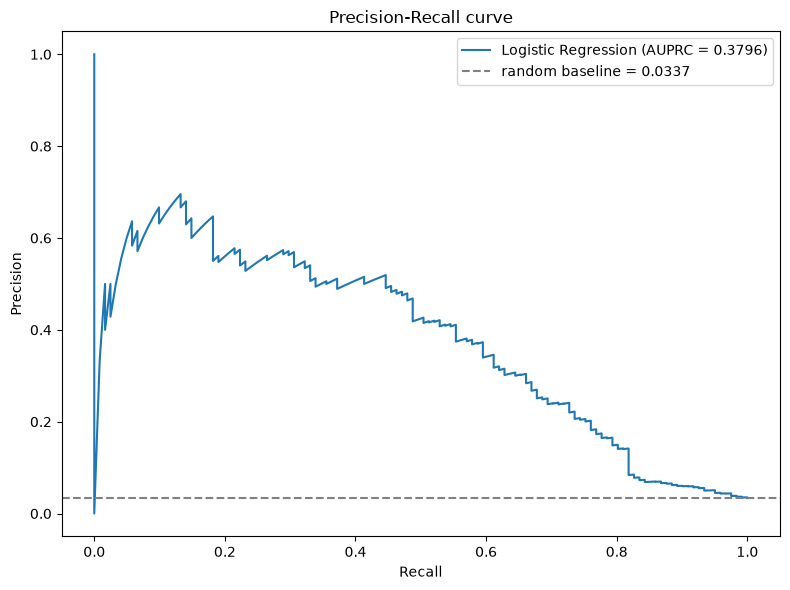

              precision    recall  f1-score   support

           0     0.9808    0.9856    0.9832      3467
           1     0.5192    0.4463    0.4800       121

    accuracy                         0.9674      3588
   macro avg     0.7500    0.7159    0.7316      3588
weighted avg     0.9652    0.9674    0.9662      3588



,threshold,predicted_positive,precision,recall,f1
0,0.05,3268,0.0364,0.9835,0.0702
1,0.10,2831,0.0417,0.9752,0.0799
2,0.15,2308,0.0498,0.9504,0.0947
3,0.20,1814,0.0601,0.9008,0.1127
4,0.25,1433,0.0712,0.8430,0.1313
5,0.30,1159,0.0854,0.8182,0.1547
6,0.35,959,0.1032,0.8182,0.1833
7,0.40,811,0.1221,0.8182,0.2124
8,0.45,669,0.1450,0.8017,0.2456
9,0.50,569,0.1652,0.7769,0.2725


In [216]:
val_probabilities = model.predict_proba_positive(X_val)
tuned_threshold = best_threshold_by_f1(y_val, val_probabilities)
display(metrics_table({
    "validation @ 0.50": evaluate_predictions(y_val, val_probabilities, 0.5),
    "validation @ tuned": evaluate_predictions(y_val, val_probabilities, tuned_threshold),
}))
print("Threshold maximising validation F1:", round(tuned_threshold, 4))

fig, ax = plt.subplots(figsize=(8, 6))
plot_precision_recall(y_val, val_probabilities, label="Logistic Regression", ax=ax)
plt.tight_layout(); plt.show()

print(classification_report(
    y_val, (val_probabilities >= tuned_threshold).astype(int), digits=4))
display(threshold_sweep(y_val, val_probabilities))

In [217]:
coefficients = pd.DataFrame({
    "feature": final_features,
    "coefficient": model.model_.named_steps["model"].coef_[0],
})
coefficients["abs"] = coefficients["coefficient"].abs()
display(coefficients.sort_values("abs", ascending=False).head(20)
        .drop(columns="abs").reset_index(drop=True))

,feature,coefficient
0,jersey_number_latest,-0.343951
1,career_observations,0.290079
2,mp_max,-0.279780
3,midmade/(midmade+midmiss)_mean,-0.276126
4,AST_per_max,-0.260449
5,TS_per_max,-0.260301
6,mp_latest,-0.256579
7,Min_per_max,-0.256179
8,GP_mean,0.256104
9,ast_latest,0.243946


In [218]:
model_performance_explanations = """
The comparison at the top of this section did not go the way the hypothesis predicted, and the result is more informative than a confirmation would have been.

For this linear model, fitting on season rows and averaging the predictions to players outperforms fitting on aggregated player rows. The reason is visible in the table itself: aggregation trades roughly 41,000 training rows for about 17,900 while tripling the feature count from 58 to 181, and a penalised linear model with only about 600 positive cases is worse conditioned under those terms. The extra features encode a career peak and a most-recent value, but a linear model can only add them up; it cannot exploit the interactions that make a richer description worthwhile.

The aggregation rule is a separate and genuinely important finding. Averaging predictions across a player's seasons beats taking the maximum, and the mechanism is the bias quantified in Section F.3: a maximum gives a four-season player four draws at the top against a one-season player's one, which inflates long college careers for a reason unrelated to NBA prospects. Any design that collapses predictions after the fact should therefore use the mean.

Two conclusions carry into the remaining experiments. First, player-level aggregation is not universally better; it is a trade, and whether it pays depends on whether the model can use the richer feature set. Experiments 2 and 3 test exactly that with models that can. Second, this comparison should not be read as settling the question for the project, only for a linear model.

The coefficient table supports the model having learned basketball-plausible relationships rather than an artefact, which is the main diagnostic value a linear baseline offers.

A limitation applies to every number here: the folds are drawn at random from within the 2008-2016 training years, while the competition scores 2020-2023 players. Experiment 3 measures that gap and finds it is not small.
"""

In [219]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view

In [220]:
# The threshold sweep is a technical artefact until expressed as scouting
# workload: given capacity to evaluate N players in depth, how many genuine
# future NBA players does that shortlist contain?
rows = []
total_positives = int(y_val.sum())
for size in (10, 25, 50, 100, 200):
    if size > len(y_val):
        continue
    cutoff = np.sort(val_probabilities)[-size]
    picked = val_probabilities >= cutoff
    found = int(y_val[picked].sum())
    rows.append({"shortlist_size": size,
                 "genuine_prospects_found": found,
                 "precision_%": round(found / picked.sum() * 100, 1),
                 "recall_%": round(found / total_positives * 100, 1),
                 "lift_vs_random": round((found / picked.sum()) / y_val.mean(), 1)})
print(f"Validation pool: {len(y_val)} players, {total_positives} reached a "
      f"sustained NBA career ({y_val.mean():.2%}).")
display(pd.DataFrame(rows))

Validation pool: 3588 players, 121 reached a sustained NBA career (3.37%).


,shortlist_size,genuine_prospects_found,precision_%,recall_%,lift_vs_random
0,10,6,60.0,5.0,17.8
1,25,17,68.0,14.0,20.2
2,50,27,54.0,22.3,16.0
3,100,50,50.0,41.3,14.8
4,200,72,36.0,59.5,10.7


In [221]:
business_impacts_explanations = """
The model's value is prioritisation rather than classification. The shortlist table reframes the threshold choice as the question a scouting department actually faces: given the capacity to evaluate a fixed number of players in depth, how many genuine future NBA players does that shortlist contain, and how many are missed?

The lift column is the operationally meaningful figure, since it states how much better the shortlist is than drawing the same number of players at random from the same pool. Even this simple linear baseline achieves a precision several times the 3.4% base rate at small shortlist sizes, which is the regime scouting departments operate in because evaluation capacity is always far smaller than the candidate pool.

Two limitations bound any practical use. False negatives are players with genuine NBA futures who never receive attention, and because the positive class is so rare, recall at a workable shortlist size is inevitably limited: the model narrows a search, it does not close it. The threshold must be chosen from the organisation's own costs and capacity rather than from validation F1, which is reported here only as a diagnostic. Predictions should be combined with film, medical assessment, interviews and expert judgement, and subgroup performance should be audited before any operational deployment.
"""

In [222]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

---
## H. Project Outcomes

In [223]:
experiment_outcome = "Hypothesis Rejected"

In [224]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [225]:
experiment_results_explanations = """
Experiment 1 rejected its own hypothesis, and that is the most useful thing it produced.

Aggregating season rows into one row per player before modelling did not improve a Logistic Regression; it made it measurably worse than fitting on season rows and averaging the predictions afterwards. The mechanism is clear from the comparison table: aggregation trades roughly 41,000 training rows for about 17,900 while tripling the feature count, and a penalised linear model with about 600 positive cases cannot turn the richer description into an advantage because it can only add features up, never combine them.

This reframes the project's central design question rather than settling it. Player-level aggregation is a trade, not a free improvement, and whether it pays depends on whether the model can exploit interactions among the additional features. Experiments 2 and 3 test precisely that with a Random Forest and a gradient booster.

A second finding stands on its own and is independent of the model. When predictions are collapsed to players after the fact, the mean clearly beats the maximum. The maximum gives a four-season player four draws at the top against a one-season player's one, while the underlying positive rate rises only from about 3.1% to 3.7% across that range, so the rule inflates long college careers for a reason unrelated to NBA prospects.

Two further results are worth carrying forward. Parsing the three text columns recovered height, age and jersey number, which a numeric-only selection would have discarded silently. And the linear coefficients are basketball-plausible, which is the main diagnostic value this baseline offers.

The limitations are the model's own. Logistic Regression cannot represent interactions, and it requires median imputation because it cannot consume missing values, which erases the information carried by a statistic being absent when absence is itself informative here. Both motivate the experiments that follow. A limitation of the evaluation also carries forward: these folds are drawn from within the training years and cannot measure how well any of this transfers to the 2020-2023 test cohort.
"""

In [226]:
# Do not modify this code
print_tile(size="h3", key='experiment_results_explanations', value=experiment_results_explanations)

---
## Kaggle Submission

The model predicts one score per player, so no aggregation step is needed here. That is the point of the player-level design: the unit the model was fitted on is the unit the competition scores.

In [227]:
final_model = RankScorer(build_logistic_pipeline(C=best_C)).fit(X_all, y_all)
kaggle_scores = final_model.predict_rank_score(X_kaggle)
submission = build_submission(test_pids, kaggle_scores, as_ranks=True)

save_model(final_model, REPO / "models" /
           "36120-26SP-group38-25740655-experiment-1-logistic.joblib")
print("Players predicted:", len(submission))
display(submission.head())

Players predicted: 6261


,pid,label
0,27085,0.368072
1,30747,0.275116
2,32932,0.526833
3,33635,0.921019
4,33955,0.953761


In [228]:
# Validates columns, row count, id uniqueness, missing values, the [0, 1] range,
# and that the id set matches the competition's sample submission exactly.
submission_dir = (Path("/content/drive/MyDrive/AML_AT1")
                  if Path("/content/drive").exists()
                  else REPO / "data" / "processed")
submission_path = save_submission(
    submission,
    submission_dir / "36120-26SP-group38-25740655-experiment-1-submission.csv",
    sample_submission=sample_submission,
)
print("Submission passed all validation checks.")
print("Saved to:", submission_path.resolve())

Submission passed all validation checks.
Saved to: /Users/shreeyapatil/Downloads/NEW ASSIGNMENTB 1/FINAL/36120-26SP-group38-experiments/data/processed/36120-26SP-group38-25740655-experiment-1-submission.csv
